# 04 — Temporal: evolução das séries do painel (2015-2025)

Passo 2 do roteiro de EDA (`docs/02_roteiro_eda.md`): plotar cada série do painel ao longo do tempo. Como o painel é mensal, a visão temporal já deve mostrar coisas que a univariada (passo 1, `01_eda_painel_2015_2025.ipynb`) não mostra — porque o histograma/boxplot resume a série inteira em uma distribuição só, sem ordem no tempo:

- a disparada do câmbio em 2015/16 e em 2020;
- se `credito_total` acompanha o câmbio, ou se move de um jeito independente;
- sazonalidade em `exportação_fob`/`importação_fob`/`exportação_kg`/`importação_kg` — um padrão que se repete todo ano, dentro de cada ano.

Numeração: como registrado no roteiro, `02` e `03` foram extensões pontuais nascidas de achados do passo 1 e não seguem a ordem numérica do roteiro. Este notebook retoma a sequência a partir do passo 2 (Temporal).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from IPython.display import display, Markdown

painel = pd.read_csv('https://raw.githubusercontent.com/vicleme/port-of-santos-credit-fx/refs/heads/main/data/processed/painel_2015_2025.csv')
painel['data'] = pd.to_datetime(painel['ano'].astype(str) + '-' + painel['mes'].astype(str) + '-01')
painel.head(2)

,ano,mes,cambio_venda,ativo_total,credito_emprestimos_titulos,credito_financiamentos,credito_outras_operacoes,credito_total,passivo_total,exportação_fob,importação_fob,exportação_kg,importação_kg,data
0,2015,1,2.6623,3.483431e+10,2.571444e+09,304829194.0,78318169.0,1.002071e+10,3.483431e+10,3.559136e+09,4.610173e+09,4.703620e+09,1.970297e+09,2015-01-01
1,2015,2,2.8782,3.293911e+10,2.571864e+09,306515589.0,77453579.0,7.849779e+09,3.293911e+10,3.151947e+09,3.918598e+09,2.776368e+09,1.637549e+09,2015-02-01


## 1. Câmbio (`cambio_venda`) ao longo do tempo

O boxplot do passo 1 mostrou a distribuição de `cambio_venda` no período inteiro, mas não em que ordem os valores altos e baixos aconteceram. Aqui plotamos a série completa, mês a mês, e destacamos as duas janelas em que o roteiro aponta uma disparada: 2015/16 e 2020.

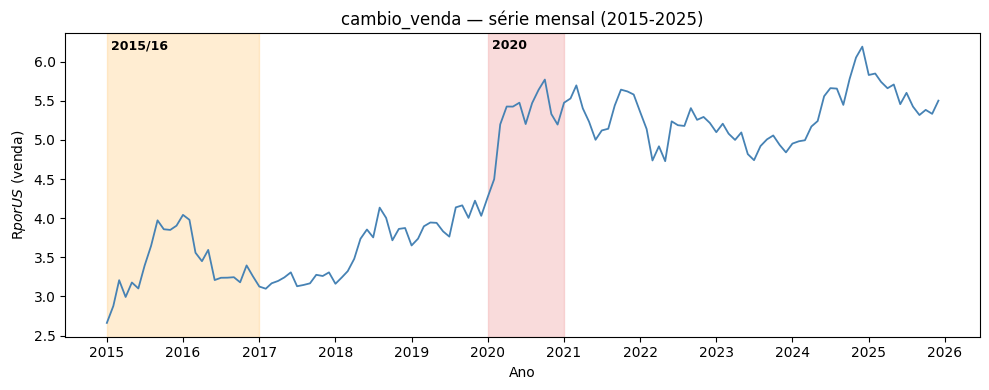

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(painel['data'], painel['cambio_venda'], color='steelblue', linewidth=1.3)
ax.set_ylabel('R$ por US$ (venda)')
ax.set_xlabel('Ano')
ax.set_title('cambio_venda — série mensal (2015-2025)')

for inicio, fim, label, cor in [
    ('2015-01-01', '2016-12-31', '2015/16', '#ffcc80'),
    ('2020-01-01', '2020-12-31', '2020', '#ef9a9a'),
]:
    ax.axvspan(pd.Timestamp(inicio), pd.Timestamp(fim), color=cor, alpha=0.35)
    ax.annotate(label, xy=(pd.Timestamp(inicio), ax.get_ylim()[1]), xytext=(3, -12),
                textcoords='offset points', fontsize=9, fontweight='600')

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()

In [3]:
cambio_2015 = painel.loc[(painel['ano'] == 2015) & (painel['mes'] == 1), 'cambio_venda'].iloc[0]
cambio_2015_pico = painel.loc[painel['ano'].isin([2015, 2016]), 'cambio_venda'].max()
cambio_2020_ini = painel.loc[(painel['ano'] == 2020) & (painel['mes'] == 1), 'cambio_venda'].iloc[0]
cambio_2020_pico = painel.loc[painel['ano'] == 2020, 'cambio_venda'].max()
mes_pico_2020 = painel.loc[(painel['ano'] == 2020) & (painel['cambio_venda'] == cambio_2020_pico), 'mes'].iloc[0]

texto = (
    f"**2015/16**: o câmbio sai de R\\$ {cambio_2015:.2f} em janeiro/2015 e sobe até "
    f"R\\$ {cambio_2015_pico:.2f} — alta de **{(cambio_2015_pico/cambio_2015 - 1)*100:.0f}%** em menos de dois anos, "
    "concentrada sobretudo entre março e setembro de 2015 (os maiores saltos mensais de toda a série estão nessa janela). "
    "A partir de 2016 o câmbio oscila, mas não volta ao patamar de 2015.\n\n"
    f"**2020**: nova disparada, de R\\$ {cambio_2020_ini:.2f} em janeiro para um pico de "
    f"R\\$ {cambio_2020_pico:.2f} em {['jan','fev','mar','abr','mai','jun','jul','ago','set','out','nov','dez'][mes_pico_2020-1]}/2020 — "
    f"alta de **{(cambio_2020_pico/cambio_2020_ini - 1)*100:.0f}%** em poucos meses, coincidindo com o início da pandemia.\n\n"
    "As duas janelas confirmam a leitura do roteiro: são disparadas rápidas e concentradas, não uma tendência suave. "
    "Fora delas, a série segue com patamar mais alto a cada novo ciclo (2015 termina em ~R\\$3,90; 2020 termina em ~R\\$5,20; "
    "2024/25 fica acima de R\\$5,70) — ou seja, o câmbio tem uma tendência de fundo crescente ao longo de todo o painel, "
    "além dos dois choques pontuais. Essa tendência é o motivo pelo qual o passo 5 (estacionariedade) é obrigatório antes de "
    "qualquer regressão: uma série com tendência correlaciona com qualquer outra série que também tenha tendência, mesmo sem "
    "relação causal real (regressão espúria)."
)
display(Markdown(texto))

**2015/16**: o câmbio sai de R\$ 2.66 em janeiro/2015 e sobe até R\$ 4.04 — alta de **52%** em menos de dois anos, concentrada sobretudo entre março e setembro de 2015 (os maiores saltos mensais de toda a série estão nessa janela). A partir de 2016 o câmbio oscila, mas não volta ao patamar de 2015.

**2020**: nova disparada, de R\$ 4.27 em janeiro para um pico de R\$ 5.77 em out/2020 — alta de **35%** em poucos meses, coincidindo com o início da pandemia.

As duas janelas confirmam a leitura do roteiro: são disparadas rápidas e concentradas, não uma tendência suave. Fora delas, a série segue com patamar mais alto a cada novo ciclo (2015 termina em ~R\$3,90; 2020 termina em ~R\$5,20; 2024/25 fica acima de R\$5,70) — ou seja, o câmbio tem uma tendência de fundo crescente ao longo de todo o painel, além dos dois choques pontuais. Essa tendência é o motivo pelo qual o passo 5 (estacionariedade) é obrigatório antes de qualquer regressão: uma série com tendência correlaciona com qualquer outra série que também tenha tendência, mesmo sem relação causal real (regressão espúria).

## 2. `credito_total` acompanha o câmbio?

O painel principal (`painel_2015_2025.csv`) tem `credito_total` como NaN nos últimos 3 meses de 2025 (out-dez), porque a fonte gratuita do ESTBAN via Base dos Dados cobre só até 2025-09 — o `matplotlib` simplesmente deixa um buraco na linha nesses meses, o que já é uma pista visual do que o passo 3 (tratamento de NaNs) vai ter que decidir.

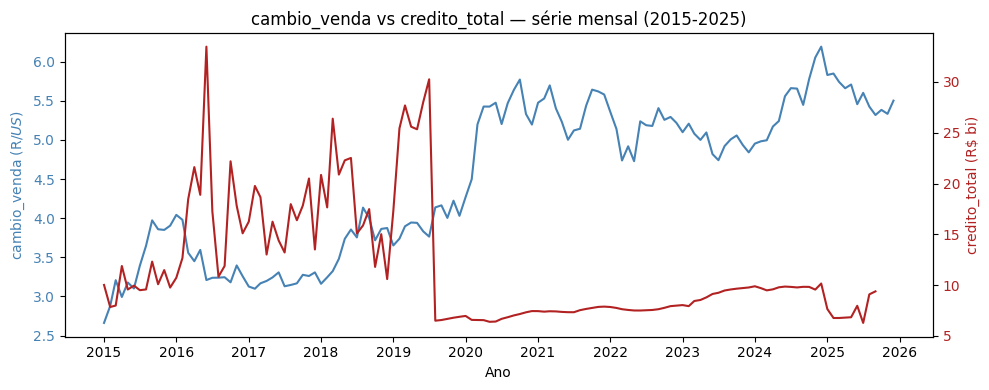

In [4]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(painel['data'], painel['cambio_venda'], color='steelblue')
ax1.set_ylabel('cambio_venda (R$/US$)', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.set_xlabel('Ano')
ax1.set_title('cambio_venda vs credito_total — série mensal (2015-2025)')

ax2 = ax1.twinx()
ax2.plot(painel['data'], painel['credito_total'] / 1e9, color='firebrick')
ax2.set_ylabel('credito_total (R$ bi)', color='firebrick')
ax2.tick_params(axis='y', labelcolor='firebrick')

ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()

In [5]:
corr_geral = painel['cambio_venda'].corr(painel['credito_total'])

anual = painel.groupby('ano')[['cambio_venda', 'credito_total']].mean()
credito_2019 = anual.loc[2019, 'credito_total']
credito_2020 = anual.loc[2020, 'credito_total']
queda_2020 = (1 - credito_2020 / credito_2019) * 100

texto = (
    f"Correlação simples entre `cambio_venda` e `credito_total` no período inteiro: **{corr_geral:.2f}** — "
    "negativa, o que à primeira vista sugeriria que crédito cai quando o câmbio sobe. Mas olhando a média anual "
    "das duas séries, essa correlação não é um movimento contínuo — é dominada por uma quebra de regime em 2020:\n\n"
    "- **2015-2019**: câmbio e `credito_total` sobem *juntos* (câmbio de R\\$3,39 para R\\$3,94; crédito de "
    f"R\\${credito_2019/1e9:.1f} bi, vindo de R\\${anual.loc[2015, 'credito_total']/1e9:.1f} bi em 2015) — nessa "
    "janela, os dois teriam correlação positiva se olhados isoladamente.\n"
    f"- **2020**: o câmbio dispara (ver seção 1) e `credito_total` desaba **{queda_2020:.0f}%** no mesmo ano "
    f"(R\\${credito_2019/1e9:.1f} bi → R\\${credito_2020/1e9:.1f} bi).\n"
    "- **2021-2025**: o câmbio permanece no patamar alto pós-2020, e `credito_total` não volta ao nível "
    "pré-2020 — fica oscilando bem abaixo, sem acompanhar as variações menores do câmbio nesse trecho.\n\n"
    "Ou seja: não dá pra ler essa correlação negativa como 'câmbio alto reduz crédito' de forma direta e contínua — "
    "o que os dados mostram é uma relação que muda de sinal ao redor de 2020, o que é mais um indício de que ambas "
    "as séries têm tendência/quebra estrutural própria do que de uma relação causal estável. Fica para o passo 4 "
    "(correlação, com o dado já tratado) e o passo 5 (estacionariedade) confirmar isso com mais rigor."
)
display(Markdown(texto))

Correlação simples entre `cambio_venda` e `credito_total` no período inteiro: **-0.63** — negativa, o que à primeira vista sugeriria que crédito cai quando o câmbio sobe. Mas olhando a média anual das duas séries, essa correlação não é um movimento contínuo — é dominada por uma quebra de regime em 2020:

- **2015-2019**: câmbio e `credito_total` sobem *juntos* (câmbio de R\$3,39 para R\$3,94; crédito de R\$17.8 bi, vindo de R\$10.0 bi em 2015) — nessa janela, os dois teriam correlação positiva se olhados isoladamente.
- **2020**: o câmbio dispara (ver seção 1) e `credito_total` desaba **62%** no mesmo ano (R\$17.8 bi → R\$6.8 bi).
- **2021-2025**: o câmbio permanece no patamar alto pós-2020, e `credito_total` não volta ao nível pré-2020 — fica oscilando bem abaixo, sem acompanhar as variações menores do câmbio nesse trecho.

Ou seja: não dá pra ler essa correlação negativa como 'câmbio alto reduz crédito' de forma direta e contínua — o que os dados mostram é uma relação que muda de sinal ao redor de 2020, o que é mais um indício de que ambas as séries têm tendência/quebra estrutural própria do que de uma relação causal estável. Fica para o passo 4 (correlação, com o dado já tratado) e o passo 5 (estacionariedade) confirmar isso com mais rigor.

## 3. Comércio exterior — valor (`exportação_fob` / `importação_fob`)

Agora as séries de comércio exterior pelo Porto de Santos, em valor (US$ FOB).

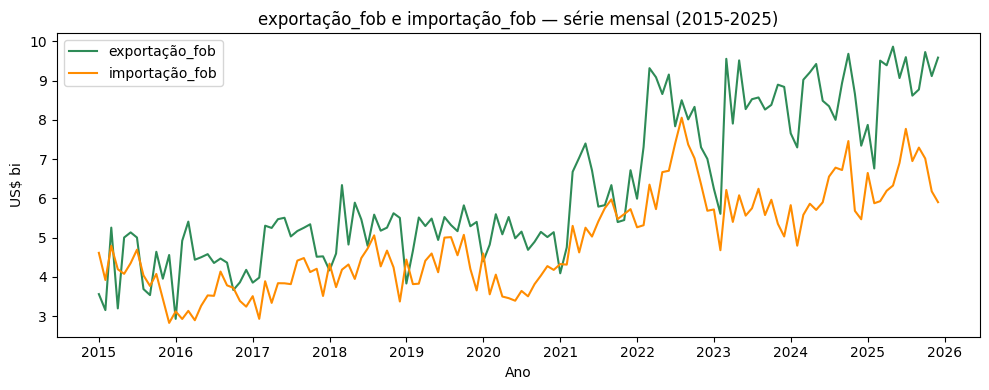

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(painel['data'], painel['exportação_fob'] / 1e9, label='exportação_fob', color='seagreen')
ax.plot(painel['data'], painel['importação_fob'] / 1e9, label='importação_fob', color='darkorange')
ax.set_ylabel('US$ bi')
ax.set_xlabel('Ano')
ax.set_title('exportação_fob e importação_fob — série mensal (2015-2025)')
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()

## 4. Comércio exterior — peso (`exportação_kg` / `importação_kg`)

Mesma ideia, mas em volume físico (kg), pra comparar com o valor em dólares da seção anterior.

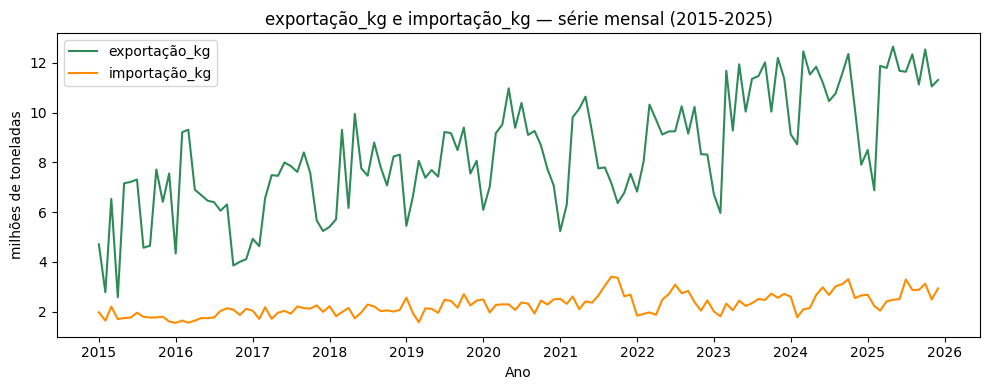

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(painel['data'], painel['exportação_kg'] / 1e9, label='exportação_kg', color='seagreen')
ax.plot(painel['data'], painel['importação_kg'] / 1e9, label='importação_kg', color='darkorange')
ax.set_ylabel('milhões de toneladas')
ax.set_xlabel('Ano')
ax.set_title('exportação_kg e importação_kg — série mensal (2015-2025)')
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()

## 5. Sazonalidade — existe um padrão que se repete todo ano?

As duas seções acima já dão uma pista visual de sazonalidade (picos e vales que parecem se repetir em certos meses todo ano), mas é fácil confundir sazonalidade real com ruído normal olhando só a série inteira. Para isolar o padrão, agrupamos por mês do ano (1 a 12), tirando a média de cada variável nesse mês ao longo dos 11 anos do painel — isso cancela a tendência de longo prazo e sobra só o formato dentro do ano.

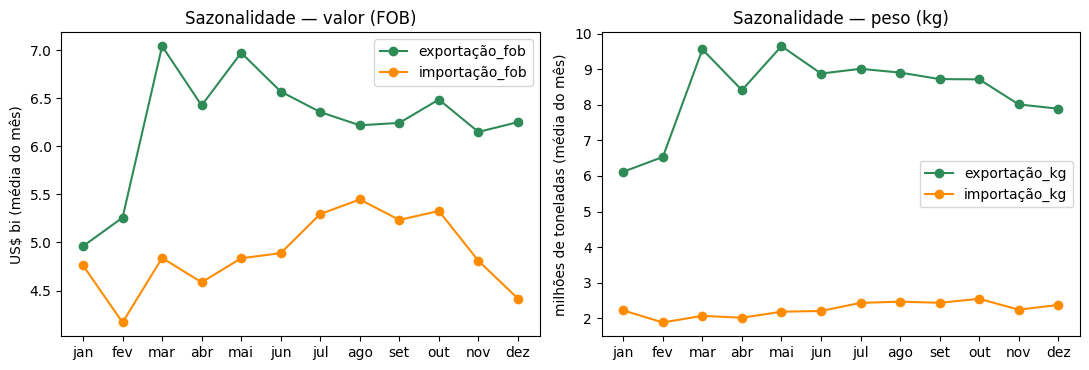

Coeficiente de variação sazonal (desvio-padrão das médias mensais / média geral, em %) — quanto maior, mais forte a sazonalidade: exportação_fob **9.7%**, importação_fob **7.9%**, exportação_kg **13.0%**, importação_kg **8.9%**. Todos moderados (nenhum acima de ~13%), mas com um padrão consistente:

- **Exportação** (valor e peso) tem o vale em jan/fev e o pico em mai, com jan sendo o mês mais fraco — coerente com o calendário de safra agrícola brasileira, que é a maior parte da carga que sai pelo Porto de Santos.
- **Importação** sobe de forma mais gradual ao longo do ano, com pico em ago (valor) — um perfil mais achatado que o da exportação, sem um vale tão marcado.

O padrão é real, mas moderado — não é o principal fator por trás das oscilações grandes vistas nas seções 1 e 2 (que são de ano para ano, não dentro do ano). Fica registrado para o passo 3: ao decidir o tratamento de NaNs, vale evitar qualquer método (como preencher com a média geral) que apague essa sazonalidade.

In [8]:
sazonal = painel.groupby('mes')[['exportação_fob', 'importação_fob', 'exportação_kg', 'importação_kg']].mean()
meses_nome = ['jan','fev','mar','abr','mai','jun','jul','ago','set','out','nov','dez']

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(meses_nome, sazonal['exportação_fob'] / 1e9, marker='o', color='seagreen', label='exportação_fob')
axes[0].plot(meses_nome, sazonal['importação_fob'] / 1e9, marker='o', color='darkorange', label='importação_fob')
axes[0].set_ylabel('US$ bi (média do mês)')
axes[0].set_title('Sazonalidade — valor (FOB)')
axes[0].legend()

axes[1].plot(meses_nome, sazonal['exportação_kg'] / 1e9, marker='o', color='seagreen', label='exportação_kg')
axes[1].plot(meses_nome, sazonal['importação_kg'] / 1e9, marker='o', color='darkorange', label='importação_kg')
axes[1].set_ylabel('milhões de toneladas (média do mês)')
axes[1].set_title('Sazonalidade — peso (kg)')
axes[1].legend()

plt.tight_layout()
plt.show()

cv = (sazonal.std() / sazonal.mean() * 100).round(1)
mes_pico_exp_kg = meses_nome[sazonal['exportação_kg'].idxmax() - 1]
mes_vale_exp_kg = meses_nome[sazonal['exportação_kg'].idxmin() - 1]
mes_pico_imp_fob = meses_nome[sazonal['importação_fob'].idxmax() - 1]

texto = (
    "Coeficiente de variação sazonal (desvio-padrão das médias mensais / média geral, em %) — quanto maior, "
    f"mais forte a sazonalidade: exportação_fob **{cv['exportação_fob']}%**, importação_fob **{cv['importação_fob']}%**, "
    f"exportação_kg **{cv['exportação_kg']}%**, importação_kg **{cv['importação_kg']}%**. Todos moderados (nenhum acima "
    "de ~13%), mas com um padrão consistente:\n\n"
    f"- **Exportação** (valor e peso) tem o vale em jan/fev e o pico em {mes_pico_exp_kg}, com {mes_vale_exp_kg} sendo "
    "o mês mais fraco — coerente com o calendário de safra agrícola brasileira, que é a maior parte da carga que sai "
    "pelo Porto de Santos.\n"
    f"- **Importação** sobe de forma mais gradual ao longo do ano, com pico em {mes_pico_imp_fob} (valor) — um perfil "
    "mais achatado que o da exportação, sem um vale tão marcado.\n\n"
    "O padrão é real, mas moderado — não é o principal fator por trás das oscilações grandes vistas nas seções 1 e 2 "
    "(que são de ano para ano, não dentro do ano). Fica registrado para o passo 3: ao decidir o tratamento de NaNs, "
    "vale evitar qualquer método (como preencher com a média geral) que apague essa sazonalidade."
)
display(Markdown(texto))

## Resumo do passo 2

- `cambio_venda` tem duas disparadas rápidas e concentradas (2015/16: +52%; 2020: +35%) somadas a uma tendência de fundo crescente ao longo de todo o painel — reforça que o passo 5 (estacionariedade) é obrigatório antes de qualquer regressão.
- `credito_total` **não** acompanha o câmbio de forma contínua: os dois sobem juntos até 2019, mas `credito_total` desaba com a disparada cambial de 2020 e não recupera o patamar anterior, mesmo com o câmbio permanecendo alto depois. A correlação negativa do período inteiro é efeito dessa quebra de regime, não de um movimento inverso estável — ponto a revisitar no passo 4 (correlação) com mais rigor.
- `exportação_fob`/`importação_fob` e `exportação_kg`/`importação_kg` têm sazonalidade real, mas moderada (CV entre 8% e 13%): exportação com vale em jan/fev e pico em torno de mar-mai (calendário de safra), importação com perfil mais achatado.
- `credito_total` tem 3 meses de NaN no fim de 2025 (buraco visível nos gráficos da seção 2) — a decisão de como tratar (dropar, interpolar, ou deixar para tratar caso a caso na modelagem) fica para o passo 3.

**Próximo passo (03 do roteiro):** tratamento dos NaNs.